# Mu Ramp Analysis: Order Parameter and Structure Factor

Analyzes simulations where the Maier-Saupe interaction strength **μ** is linearly ramped between 0 and 50:
- **Order parameter** (λ = `LambdaMaierSaupe0`) vs μ for all LC lengths and both ramp directions
- **Structure factor** S(q) vs wavevector |q|, computed via 3-D FFT of density fields

## Data sources
| Type | Path |
|------|------|
| Log files | `/home/gabriel/Projects/(Mu_ramp|Longer_Mu_Ramp)/Logs/` |
| Density binaries | `/home/gabriel/Projects/(Mu_ramp|Longer_Mu_Ramp)/Density/Mu_ramp_Nb_*/` |

## Binary format (density files)
**Header (once):** `Dim` (i32), `Nx[Dim]` (i32×Dim), `L[Dim]` (f32×Dim), `ntypes` (i32)  
**Per frame:** `ρ[ntypes × M]` (f32), where M = Nx[0]×Nx[1]×Nx[2]

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.lines import Line2D
import pandas as pd
import os
import re
from glob import glob
from tqdm.notebook import tqdm

## Configuration

In [4]:
# --- Paths ---
#LOG_DIR     = "/home/gabriel/Projects/Mu_ramp/Logs"
#DENSITY_DIR = "/home/gabriel/Projects/Mu_ramp/Density"
#OUTPUT_DIR  = "/home/gabriel/Projects/Mu_ramp"
LOG_DIR     = "/home/gabriel/Projects/Longer_Mu_Ramp/Results/Logs"
DENSITY_DIR = "/home/gabriel/Projects/Longer_Mu_Ramp/Results/Density"
OUTPUT_DIR  = "/home/gabriel/Projects/Longer_Mu_Ramp/Results/Output"
# --- Ramp parameters ---
MU_MAX = 45.0          # Max μ value at the peak of the ramp
MU_MIN = 5.0           # Min μ value at the start of the ramp
RAMP_STEPS = 10000000
# --- S(k) settings ---
DENSITY_TYPE = 0       # Particle type index (0 = first type)

# Target μ values to compare in per-LC-length S(q) plots
TARGET_MU = [6, 10, 25, 50]

# --- Filename patterns ---
#LOG_RE = re.compile(r"(increasing|decreasing)_Mu_ramp_LC_length_(\d+)_rep_(\d+)\.dat")
#DEN_RE = re.compile(r"(increasing|decreasing)_Mu_ramp_LC_length_(\d+)_rep_(\d+)_den\.bin")
LOG_RE = re.compile(r"(increasing|decreasing)_Mu_ramp_LC_length_(\d+)_rep_(\d+)\.dat")
DEN_RE = re.compile(r"(increasing|decreasing)_grid_densities_Mu_ramp_LC_length_(\d+)_rep_(\d+)\.bin")


---
## Part 1 — Order Parameter Analysis
### Load log files

In [ ]:
COLS = [
    'step', 'global_step', 'Upe', 'Ubond', 'Angles',
    'Pxx', 'Pyy', 'Pzz', 'Pxy', 'Pxz', 'Pyz',
    'Gaussian0', 'MaierSaupe0', 'LambdaMaierSaupe0', 'UDBond'
]

def read_log(filepath):
    """Read a MATILDA.FT .dat log file into a DataFrame."""
    return pd.read_csv(filepath, sep=r'\s+', comment='#', header=None, names=COLS)


log_files = sorted(glob(os.path.join(LOG_DIR, "*.dat")))
print(f"Found {len(log_files)} log files:")
for f in log_files:
    print(f"  {os.path.basename(f)}")

records = []
for fp in log_files:
    m = LOG_RE.match(os.path.basename(fp))
    if not m:
        print(f"  Warning: could not parse '{os.path.basename(fp)}', skipping.")
        continue
    direction = m.group(1)
    nb        = int(m.group(2))
    rep       = int(m.group(3))

    df = read_log(fp)
    max_step = df['step'].max()

    # Map simulation step → μ
    if direction == 'increasing':
        df['mu'] = df['step'] / max_step * (MU_MAX - MU_MIN) + MU_MIN
    else:
        df['mu'] = (MU_MAX - MU_MIN) * (1.0 - df['step'] / max_step) + MU_MIN

    df['direction'] = direction
    df['nb']        = nb
    df['rep']       = rep
    records.append(df)

all_logs = pd.concat(records, ignore_index=True)
nb_values = sorted(all_logs['nb'].unique())
print(f"\nLC lengths: {nb_values}")
print(f"Total log rows: {len(all_logs)}")

Found 24 log files:
  decreasing_Mu_ramp_LC_length_12_rep_0.dat
  decreasing_Mu_ramp_LC_length_12_rep_1.dat
  decreasing_Mu_ramp_LC_length_12_rep_2.dat
  decreasing_Mu_ramp_LC_length_3_rep_0.dat
  decreasing_Mu_ramp_LC_length_3_rep_1.dat
  decreasing_Mu_ramp_LC_length_3_rep_2.dat
  decreasing_Mu_ramp_LC_length_6_rep_0.dat
  decreasing_Mu_ramp_LC_length_6_rep_1.dat
  decreasing_Mu_ramp_LC_length_6_rep_2.dat
  decreasing_Mu_ramp_LC_length_9_rep_0.dat
  decreasing_Mu_ramp_LC_length_9_rep_1.dat
  decreasing_Mu_ramp_LC_length_9_rep_2.dat
  increasing_Mu_ramp_LC_length_12_rep_0.dat
  increasing_Mu_ramp_LC_length_12_rep_1.dat
  increasing_Mu_ramp_LC_length_12_rep_2.dat
  increasing_Mu_ramp_LC_length_3_rep_0.dat
  increasing_Mu_ramp_LC_length_3_rep_1.dat
  increasing_Mu_ramp_LC_length_3_rep_2.dat
  increasing_Mu_ramp_LC_length_6_rep_0.dat
  increasing_Mu_ramp_LC_length_6_rep_1.dat
  increasing_Mu_ramp_LC_length_6_rep_2.dat
  increasing_Mu_ramp_LC_length_9_rep_0.dat
  increasing_Mu_ramp_LC_leng

ValueError: No objects to concatenate

### Plot: order parameter λ vs μ — all LC lengths

/tmp/ipykernel_139428/3751618993.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap      = plt.cm.get_cmap('tab10', len(nb_values))


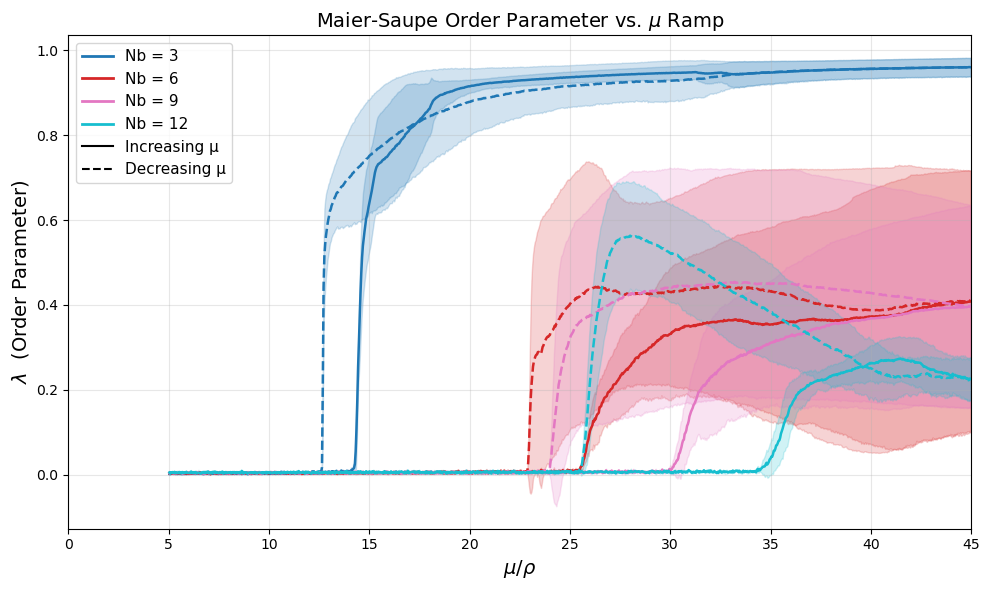

In [ ]:
cmap      = plt.cm.get_cmap('tab10', len(nb_values))
nb_colors = {nb: cmap(i) for i, nb in enumerate(nb_values)}
ls_map    = {'increasing': '-', 'decreasing': '--'}

fig, ax = plt.subplots(figsize=(10, 6))

for (nb, direction), grp in all_logs.groupby(['nb', 'direction']):
    # Compute mean and std across reps at each mu value
    stats = grp.groupby('mu')['LambdaMaierSaupe0'].agg(['mean', 'std']).reset_index()
    stats = stats.sort_values('mu')
    stats['std'] = stats['std'].fillna(0)

    color = nb_colors[nb]
    ls = ls_map[direction]
    ax.plot(stats['mu'], stats['mean'], color=color, linestyle=ls, lw=1.8)
    ax.fill_between(stats['mu'], stats['mean'] - stats['std'],
                    stats['mean'] + stats['std'], color=color, alpha=0.2)

# Legend: Nb by colour, direction by line style
legend_elems  = [Line2D([0],[0], color=nb_colors[nb], lw=2, label=f"Nb = {nb}")
                 for nb in nb_values]
legend_elems += [
    Line2D([0],[0], color='k', lw=1.5, ls='-',  label='Increasing μ'),
    Line2D([0],[0], color='k', lw=1.5, ls='--', label='Decreasing μ'),
]
ax.legend(handles=legend_elems, fontsize=11, loc='upper left')

ax.set_xlabel(r"$\mu / \rho$",                fontsize=14)
ax.set_ylabel(r"$\lambda$  (Order Parameter)", fontsize=14)
ax.set_title( r"Maier-Saupe Order Parameter vs. $\mu$ Ramp", fontsize=14)
ax.set_xlim(0, MU_MAX)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "order_parameter_vs_mu.png"), dpi=150)
plt.show()


---
## Part 2 — Structure Factor S(q)

Reads density binary files and computes S(q) via 3-D FFT of the density field:

$$S(|q|) = \left\langle |\hat{\rho}(\mathbf{q})| \right\rangle_{|\mathbf{q}|} \qquad \hat{\rho} = \mathcal{F}[\rho]$$

### Binary reader

In [ ]:
def read_density_bin(filepath, verbose=False):
    """
    Read a MATILDA.FT density binary file.

    Binary layout (calc-sk_per_frame.cpp):
      Header : Dim(i32), Nx[Dim](i32×Dim), L[Dim](f32×Dim), ntypes(i32)
      Frames : rho[ntypes × M](f32)  repeated, M = prod(Nx)

    Returns
    -------
    Dim    : int
    Nx     : int array [Dim]
    L      : float array [Dim]  (box side lengths)
    ntypes : int
    frames : float array [nframes, ntypes, *Nx]
    """
    with open(filepath, 'rb') as f:
        Dim    = np.frombuffer(f.read(4),       dtype=np.int32)[0]
        Nx     = np.frombuffer(f.read(4*Dim),   dtype=np.int32).copy()
        L      = np.frombuffer(f.read(4*Dim),   dtype=np.float32).copy()
        ntypes = np.frombuffer(f.read(4),       dtype=np.int32)[0]

        M           = int(np.prod(Nx))
        frame_bytes = 4 * ntypes * M
        raw_frames  = []
        while True:
            raw = f.read(frame_bytes)
            if len(raw) < frame_bytes:
                break
            raw_frames.append(
                np.frombuffer(raw, dtype=np.float32)
                  .reshape((ntypes,) + tuple(Nx))
                  .copy()
            )

    frames = np.array(raw_frames)   # (nframes, ntypes, *Nx)
    if verbose:
        print(f"  Dim={Dim}, Nx={Nx.tolist()}, L={L.tolist()}, "
              f"ntypes={ntypes}, nframes={len(raw_frames)}")
    return int(Dim), Nx, L, int(ntypes), frames

### S(q) computation via FFT

In [ ]:
def compute_sk_per_frame(frames, Nx, L, type_idx=0, n_bins=80):
    """
    Compute radially-averaged S(q) = |FFT(ρ)| for every frame.

    Returns
    -------
    k_centers : (n_bins,)
    sk_all    : (nframes, n_bins)
    """
    Dim = len(Nx)
    k_1d = [2*np.pi * np.fft.fftfreq(Nx[d], d=float(L[d]) / Nx[d])
            for d in range(Dim)]
    k_mag  = np.sqrt(sum(g**2 for g in np.meshgrid(*k_1d, indexing='ij')))
    k_flat = k_mag.ravel()

    mask    = k_flat > 0
    k_vals  = k_flat[mask]
    k_edges = np.linspace(0.0, k_vals.max(), n_bins + 1)
    k_cents = 0.5 * (k_edges[:-1] + k_edges[1:])
    bin_idx = np.clip(np.digitize(k_vals, k_edges) - 1, 0, n_bins - 1)

    all_sk = []
    for frame in frames:
        rho     = frame[type_idx].astype(np.float64)
        sk_full = np.abs(np.fft.fftn(rho)).ravel()[mask]

        sk_bin = np.zeros(n_bins)
        cnt    = np.zeros(n_bins, dtype=int)
        np.add.at(sk_bin, bin_idx, sk_full)
        np.add.at(cnt,    bin_idx, 1)
        ok = cnt > 0
        sk_bin[ok] /= cnt[ok]
        all_sk.append(sk_bin)

    return k_cents, np.array(all_sk)   # (nframes, n_bins)

### Load density files and compute S(q)

In [ ]:
den_files = sorted(glob(os.path.join(DENSITY_DIR, "**", "*densities*.bin"), recursive=True))
print(f"Found {len(den_files)} density files:")
for f in den_files:
    print(f"  {os.path.relpath(f, DENSITY_DIR)}")

sk_results = []

for fp in tqdm(den_files, desc="Computing S(q)"):
    m = DEN_RE.match(os.path.basename(fp))
    if not m:
        print(f"  Warning: skipping {os.path.basename(fp)}")
        continue
    direction = m.group(1)
    nb        = int(m.group(2))
    rep       = int(m.group(3))

    Dim, Nx, L, ntypes, frames = read_density_bin(fp, verbose=True)
    nframes = len(frames)

    # Assign μ to each frame via linear interpolation over the ramp
    if direction == 'increasing':
        mu_frames = np.linspace(0,      MU_MAX, nframes)
    else:
        mu_frames = np.linspace(MU_MAX, 0,      nframes)

    # Compute number of S(q) bins from box size: bin width dk = 2π/L
    dk = 2 * np.pi / L.min()
    k_max = np.sqrt(np.sum((np.pi * Nx / L)**2))
    n_bins = int(k_max / dk)

    k_cents, sk_all = compute_sk_per_frame(
        frames, Nx, L, type_idx=DENSITY_TYPE, n_bins=n_bins
    )

    sk_results.append({
        'nb':        nb,
        'direction': direction,
        'rep':       rep,
        'Nx':        Nx,
        'L':         L,
        'nframes':   nframes,
        'mu_frames': mu_frames,
        'k':         k_cents,
        'sk_all':    sk_all,               # (nframes, n_bins)
        'sk_avg':    sk_all.mean(axis=0),  # (n_bins,) — time-averaged
    })

print(f"\nDone. Computed S(q) for {len(sk_results)} files.")
nb_vals_sk = sorted(set(r['nb'] for r in sk_results))


Found 24 density files:
  Mu_ramp_Nb_12/decreasing_grid_densities_Mu_ramp_LC_length_12_rep_0.bin
  Mu_ramp_Nb_12/decreasing_grid_densities_Mu_ramp_LC_length_12_rep_1.bin
  Mu_ramp_Nb_12/decreasing_grid_densities_Mu_ramp_LC_length_12_rep_2.bin
  Mu_ramp_Nb_12/increasing_grid_densities_Mu_ramp_LC_length_12_rep_0.bin
  Mu_ramp_Nb_12/increasing_grid_densities_Mu_ramp_LC_length_12_rep_1.bin
  Mu_ramp_Nb_12/increasing_grid_densities_Mu_ramp_LC_length_12_rep_2.bin
  Mu_ramp_Nb_3/decreasing_grid_densities_Mu_ramp_LC_length_3_rep_0.bin
  Mu_ramp_Nb_3/decreasing_grid_densities_Mu_ramp_LC_length_3_rep_1.bin
  Mu_ramp_Nb_3/decreasing_grid_densities_Mu_ramp_LC_length_3_rep_2.bin
  Mu_ramp_Nb_3/increasing_grid_densities_Mu_ramp_LC_length_3_rep_0.bin
  Mu_ramp_Nb_3/increasing_grid_densities_Mu_ramp_LC_length_3_rep_1.bin
  Mu_ramp_Nb_3/increasing_grid_densities_Mu_ramp_LC_length_3_rep_2.bin
  Mu_ramp_Nb_6/decreasing_grid_densities_Mu_ramp_LC_length_6_rep_0.bin
  Mu_ramp_Nb_6/decreasing_grid_densities_

Computing S(q):   0%|          | 0/24 [00:00<?, ?it/s]

  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0,

### Plot: S(q) at selected μ values — one figure per LC length

Each figure shows both ramp directions; curves are coloured by μ value.

/tmp/ipykernel_139428/2993439025.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  mu_cmap   = plt.cm.get_cmap('plasma', len(TARGET_MU))


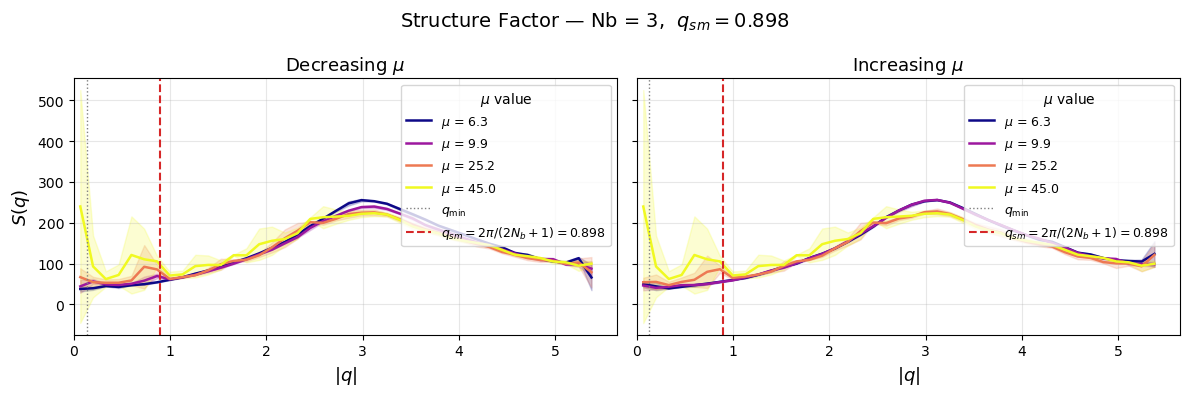

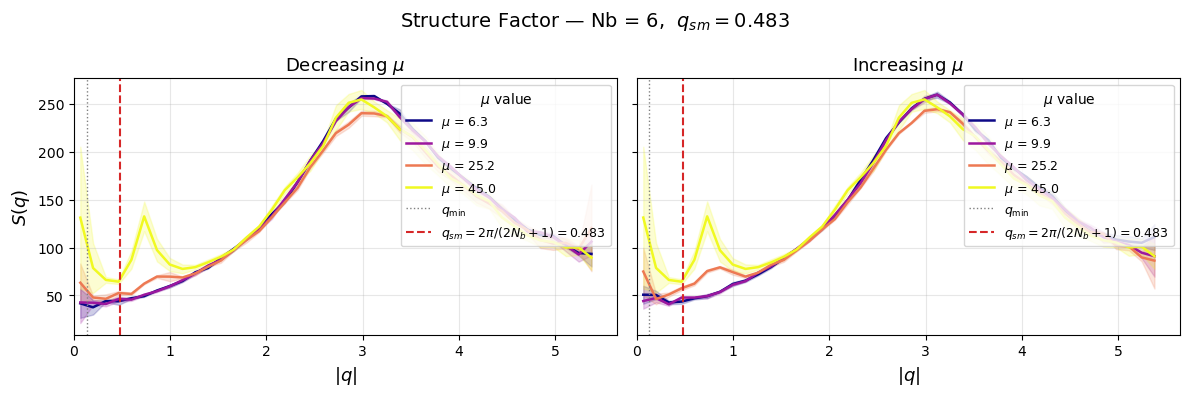

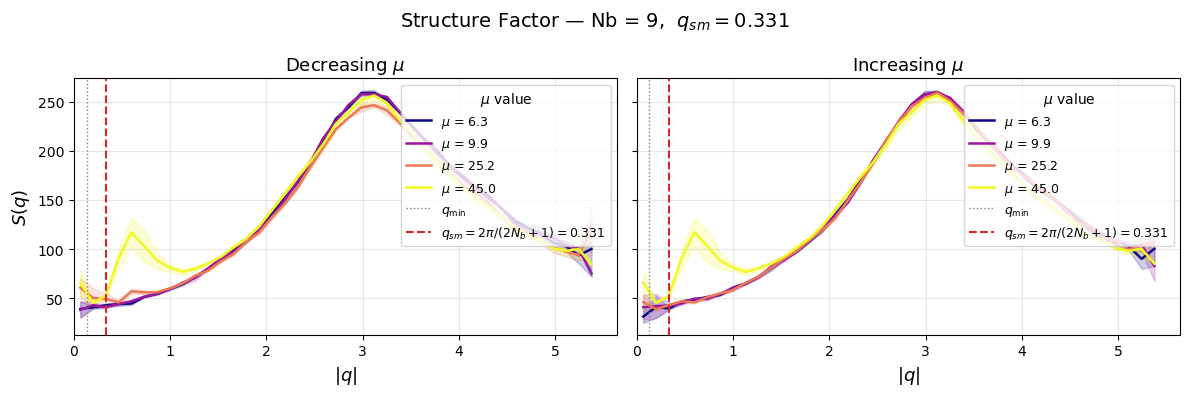

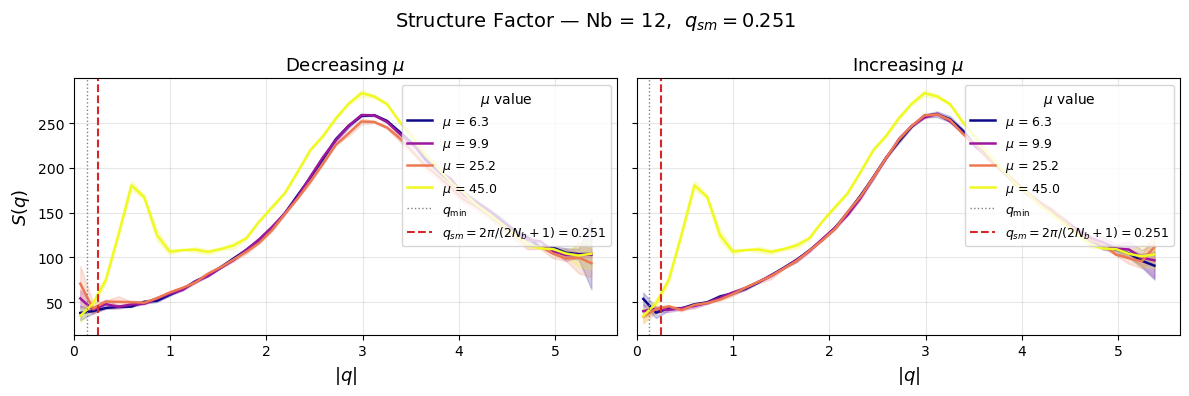

In [ ]:
mu_cmap   = plt.cm.get_cmap('plasma', len(TARGET_MU))
mu_colors = {mu: mu_cmap(i) for i, mu in enumerate(TARGET_MU)}

for nb in nb_vals_sk:
    # Group results by direction, collecting all reps
    dir_reps = {}
    for r in sk_results:
        if r['nb'] == nb:
            dir_reps.setdefault(r['direction'], []).append(r)
    directions = sorted(dir_reps.keys())

    # Expected smectic layering wavevector for this LC length
    q_smectic = 2 * np.pi / (2 * nb + 1)

    fig, axes = plt.subplots(1, len(directions), figsize=(6*len(directions), 4),
                              sharey=True)
    if len(directions) == 1:
        axes = [axes]

    for ax, direction in zip(axes, directions):
        reps = dir_reps[direction]
        ref  = reps[0]
        q_min = 2*np.pi / ref['L'].min()

        for mu_target in TARGET_MU:
            # Gather S(q) at this mu from all reps
            sk_at_mu = []
            actual_mu = None
            for rep in reps:
                frame_idx = int(np.argmin(np.abs(rep['mu_frames'] - mu_target)))
                actual_mu = rep['mu_frames'][frame_idx]
                sk_at_mu.append(rep['sk_all'][frame_idx])
            sk_at_mu = np.array(sk_at_mu)
            sk_mean = sk_at_mu.mean(axis=0)
            sk_std  = sk_at_mu.std(axis=0) if len(sk_at_mu) > 1 else np.zeros_like(sk_mean)

            color = mu_colors[mu_target]
            ax.plot(ref['k'], sk_mean, color=color, lw=1.8,
                    label=fr"$\mu$ = {actual_mu:.1f}")
            ax.fill_between(ref['k'], sk_mean - sk_std, sk_mean + sk_std,
                            color=color, alpha=0.2)

        ax.axvline(x=q_min,     color='gray',       ls=':',  lw=1.0,
                   label=r'$q_{\min}$')
        ax.axvline(x=q_smectic, color='tab:red',    ls='--', lw=1.5,
                   label=fr'$q_{{sm}} = 2\pi/(2N_b+1) = {q_smectic:.3f}$')

        ax.set_xlabel(r"$|q|$",                        fontsize=13)
        ax.set_title(direction.capitalize() + r" $\mu$", fontsize=13)
        ax.set_xlim(left=0)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=9, title=r"$\mu$ value", loc='upper right')

    axes[0].set_ylabel(r"$S(q)$", fontsize=13)
    fig.suptitle(fr"Structure Factor — Nb = {nb},  $q_{{sm}} = {q_smectic:.3f}$",
                 fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"sk_vs_mu_nb{nb}.png"), dpi=150)
    plt.show()


### Plot: S(q) evolution as a function of μ — heatmap (one figure per LC length)

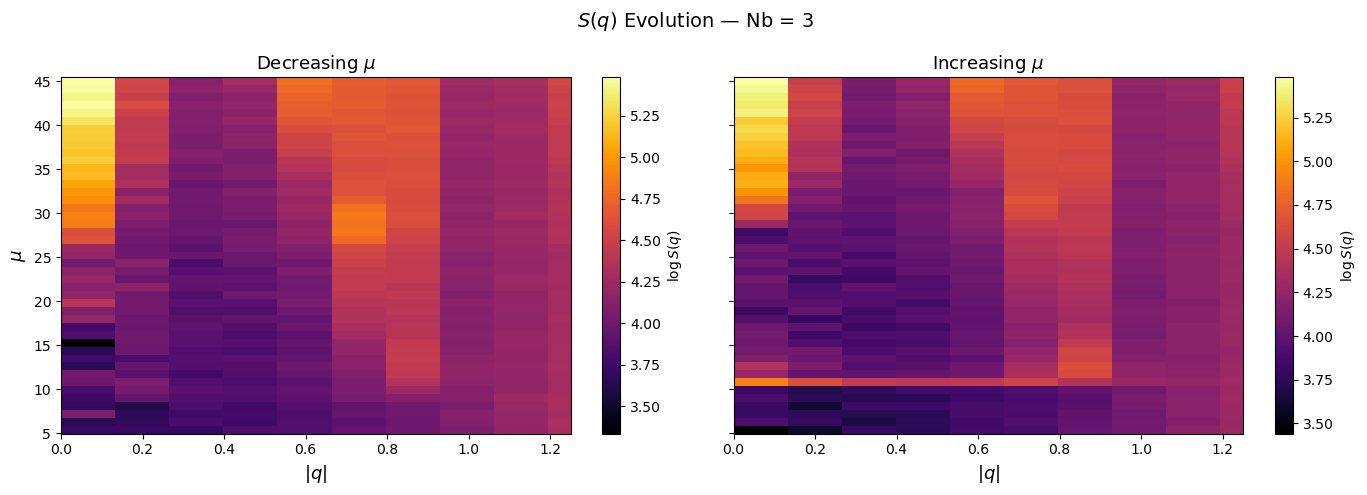

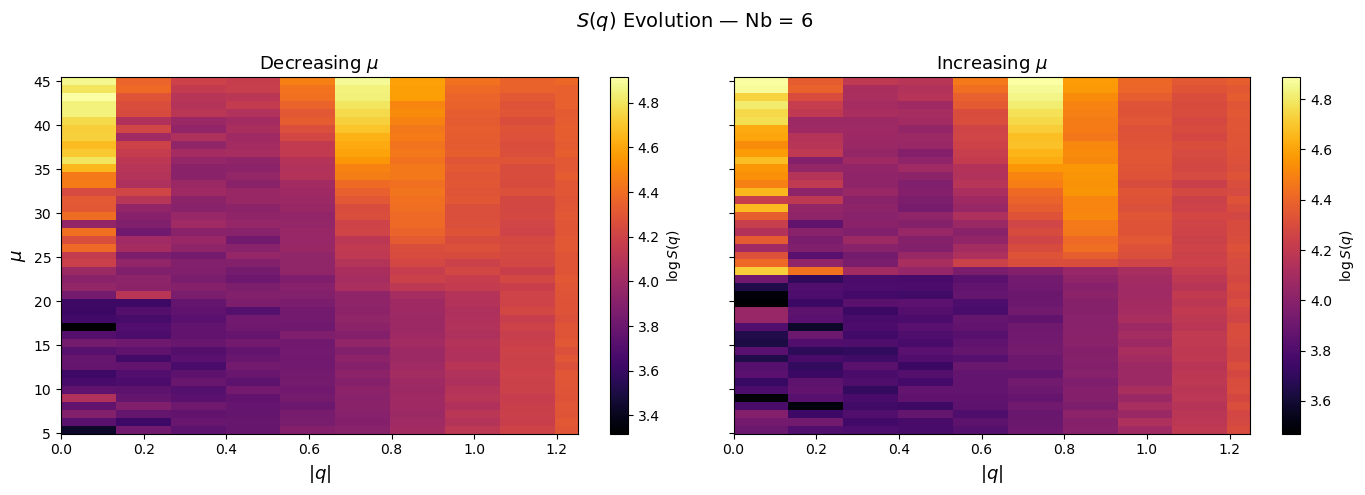

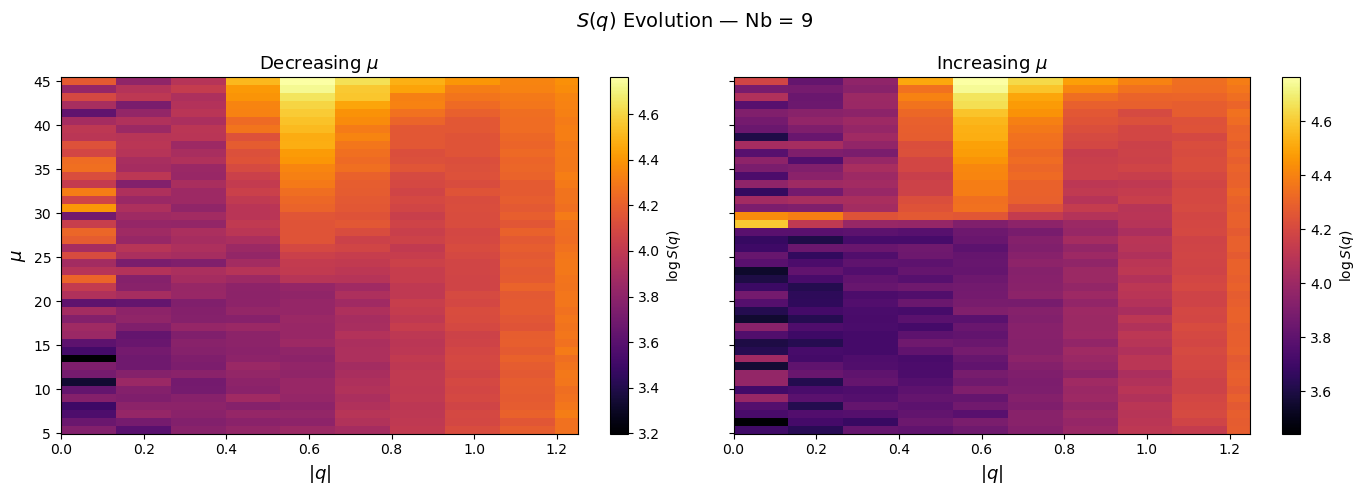

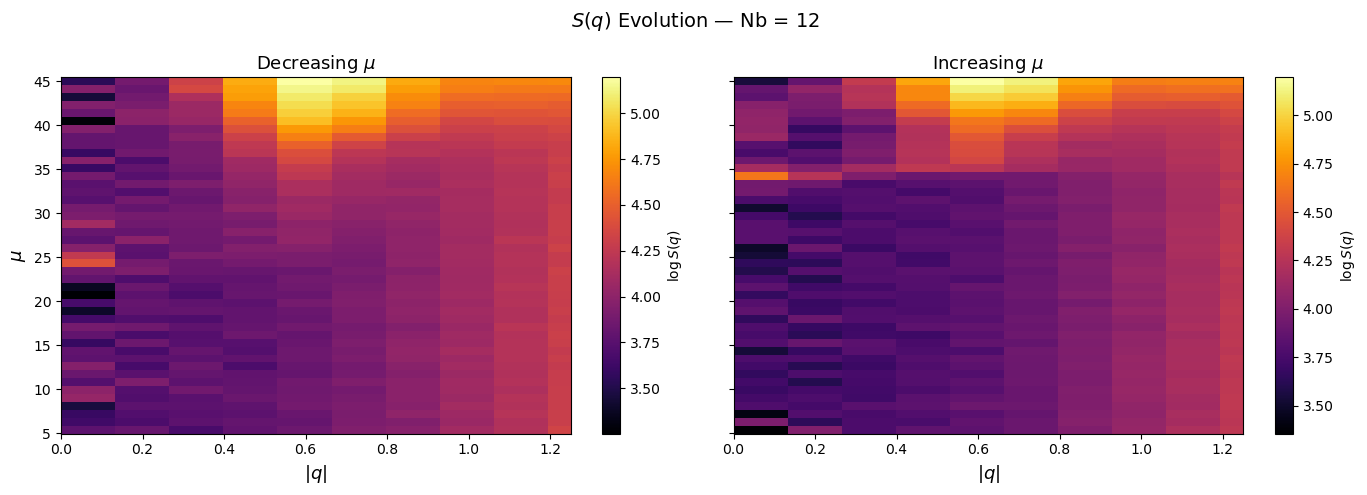

In [ ]:
Q_MAX_PLOT = 1.25

for nb in nb_vals_sk:
    # Group results by direction, collecting all reps
    dir_reps = {}
    for r in sk_results:
        if r['nb'] == nb:
            dir_reps.setdefault(r['direction'], []).append(r)
    directions = sorted(dir_reps.keys())

    q_smectic = 2 * np.pi / (2 * nb + 1)

    fig, axes = plt.subplots(1, len(directions), figsize=(7*len(directions), 5),
                              sharey=True)
    if len(directions) == 1:
        axes = [axes]

    for ax, direction in zip(axes, directions):
        reps = dir_reps[direction]
        ref  = reps[0]
        k    = ref['k']
        mu   = ref['mu_frames']

        # Average S(q) heatmap across reps
        sk_stack = np.array([rep['sk_all'] for rep in reps])
        sk_mean  = sk_stack.mean(axis=0)

        # Filter to mu >= MU_MIN only
        mu_mask = mu >= MU_MIN
        mu_filt = mu[mu_mask]
        sk_filt = sk_mean[mu_mask, :]

        # Determine colorbar limits from the visible region: mu >= MU_MIN and q < Q_MAX_PLOT
        q_mask = k <= Q_MAX_PLOT
        sk_visible = sk_filt[:, q_mask]
        sk_log = np.log(sk_visible + 1e-10)  # Add small offset to avoid log(0)
        vmin = sk_log.min()
        vmax = sk_log.max()

        # Sort frames by mu for consistent axis ordering
        sort_idx = np.argsort(mu_filt)
        mu_sorted = mu_filt[sort_idx]
        sk_sorted = sk_filt[sort_idx, :]
        sk_sorted_log = np.log(sk_sorted + 1e-10)

        im = ax.pcolormesh(k, mu_sorted, sk_sorted_log, shading='auto',
                           cmap='inferno', vmin=vmin, vmax=vmax)
        ax.set_xlabel(r"$|q|$", fontsize=13)
        ax.set_xlim(0, Q_MAX_PLOT)
        ax.set_title(direction.capitalize() + r" $\mu$", fontsize=13)
        plt.colorbar(im, ax=ax, label=r"$\log S(q)$")

    axes[0].set_ylabel(r"$\mu$", fontsize=13)
    fig.suptitle(fr"$S(q)$ Evolution — Nb = {nb}",
                 fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"sk_heatmap_nb{nb}.png"), dpi=150)
    plt.show()


---
## Part 3 — Local Smectic Order Parameter (McMillan)

Reads GSD trajectory files and computes the McMillan local smectic order parameters
$\tau$ (translational) and $\sigma$ (orientational-translational coupling) per frame:

$$\tau = \frac{1}{N}\sum_k \cos(q_0\, \mathbf{r}_k \cdot \hat{n})$$

$$\sigma = \frac{1}{N}\sum_k P_2(\hat{u}_k \cdot \hat{n})\, \cos(q_0\, \mathbf{r}_k \cdot \hat{n})$$

where $q_0 = 2\pi / N_b$ is the smectic wavevector (fallback; refined by 1-D FFT), $\hat{n}$ is the local voxel nematic director, and $P_2(x) = (3x^2-1)/2$.

**Pipeline per frame:**
1. Parse GSD → molecular CoMs and orientations (PBC-aware)
2. Voxelize box into sub-regions of edge ≈ `VOXEL_SIZE_FACTOR × Nb`
3. Compute local nematic director per voxel via `freud.order.Nematic`
4. Determine $q_0$ via 1-D FFT of projected CoM histogram (fallback: $2\pi/N_b$)
5. Average McMillan τ, σ over valid voxels → one scalar pair per frame

Results are cached per run as `.pkl` files; re-run is skipped on kernel resets.

In [1]:
import subprocess, sys
for pkg in ["gsd", "freud-analysis"]:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", pkg], check=True)
print("Packages ready.")

Packages ready.


In [5]:
import gsd.hoomd
import freud
from scipy.fft import rfft
import pickle
from pathlib import Path

# GSD directory and filename pattern
GSD_DIR = "/home/gabriel/Projects/Longer_Mu_Ramp/Results/GSD"
GSD_RE  = re.compile(r"(increasing|decreasing)_Mu_ramp_LC_length_(\d+)_rep_(\d+)\.gsd")

# Smectic analysis parameters
VOXEL_SIZE_FACTOR  = 4    # voxel edge ≈ factor × Nb (bead units)
MIN_MOLS_PER_VOXEL = 10   # skip voxels below this occupancy

# ── Cache configuration (mirrors NP_confined_PS_analysis pattern) ─────────
SMECTIC_CACHE_DIR = Path("/home/gabriel/Projects/Longer_Mu_Ramp/Results/cache")
SMECTIC_CACHE_DIR.mkdir(exist_ok=True)
FORCE_RECOMPUTE = False   # set True to ignore all caches and recompute everything

def _smectic_cache_path(nb, direction, rep, vsf, mmpv):
    """Return Path for a per-run smectic cache file."""
    return SMECTIC_CACHE_DIR / f"smectic_nb{nb}_{direction}_rep{rep}_vsf{vsf}_mmpv{mmpv}.pkl"

def _load_pkl(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

def _save_pkl(obj, path):
    with open(path, 'wb') as f:
        pickle.dump(obj, f)

print(f"Cache dir: {SMECTIC_CACHE_DIR}")
print(f"FORCE_RECOMPUTE = {FORCE_RECOMPUTE}")

Cache dir: /home/gabriel/Projects/Longer_Mu_Ramp/Results/cache
FORCE_RECOMPUTE = False


In [6]:
def parse_molecular_orientations(pos, mol_ids, L):
    """
    Compute per-molecule centre-of-mass and end-to-end unit orientation vector.

    Parameters
    ----------
    pos     : ndarray (N, 3)  — particle positions from GSD (HOOMD convention, range ~ [-L/2, L/2])
    mol_ids : ndarray (N,)    — integer molecule IDs (0-indexed)
    L       : float           — cubic box side length

    Returns
    -------
    r_com : ndarray (n_mol, 3)  — CoM wrapped to [0, L)
    u_hat : ndarray (n_mol, 3)  — unit end-to-end orientation vector
    """
    n_mol = int(mol_ids.max()) + 1
    nb    = len(mol_ids) // n_mol

    # Stable sort by molecule ID preserves bead ordering within each chain
    sort_idx = np.argsort(mol_ids, kind='stable')
    pos_mol  = pos[sort_idx].reshape(n_mol, nb, 3)  # (n_mol, nb, 3)

    # PBC-aware CoM: anchor to first bead, apply minimum-image to displacements
    ref    = pos_mol[:, 0:1, :]                          # (n_mol, 1, 3)
    deltas = pos_mol - ref
    deltas -= L * np.round(deltas / L)
    r_com  = (ref[:, 0, :] + deltas.mean(axis=1)) % L   # wrap to [0, L)

    # End-to-end orientation with minimum-image convention
    diff  = pos_mol[:, -1, :] - pos_mol[:, 0, :]
    diff -= L * np.round(diff / L)
    norms = np.linalg.norm(diff, axis=1, keepdims=True)
    norms = np.where(norms > 1e-12, norms, 1.0)  # guard zero-length chains
    u_hat = diff / norms

    return r_com, u_hat


In [7]:
def compute_local_smectic_order(pos, mol_ids, L,
                                voxel_size_factor=4,
                                min_mols_per_voxel=10):
    """
    Full McMillan local smectic order pipeline for one GSD frame.

    τ and σ use the phase-invariant complex-exponential formulation:
      τ = |<exp(i q₀ r·n)>|         (amplitude of density wave)
      σ = |<P₂(u·n) exp(i q₀ r·n)>| (amplitude of coupled order)

    q₀ = 2π/Nb is always used.  The earlier FFT refinement was removed because
    in the disordered phase the FFT selects long-wavelength noise peaks
    (k_idx=1, q₀ ≈ 2π/s_range << 2π/Nb), which gives spuriously large τ
    through a finite-size sinc artefact.  In the smectic phase the physical
    q₀ = 2π/Nb is correct by construction.

    Returns (tau, sigma) averaged over valid voxels, or (nan, nan) if none qualify.
    """
    n_mol   = int(mol_ids.max()) + 1
    nb_mol  = len(mol_ids) // n_mol
    q0      = 2.0 * np.pi / nb_mol   # always use the physical smectic wavevector

    r_com, u_hat = parse_molecular_orientations(pos, mol_ids, L)

    # ── Voxelization ───────────────────────────────────────────────────────
    n_vox      = max(2, int(L / (voxel_size_factor * nb_mol)))
    voxel_edge = L / n_vox

    vox_idx  = (r_com / voxel_edge).astype(int) % n_vox
    vox_flat = (vox_idx[:, 0] * n_vox**2
              + vox_idx[:, 1] * n_vox
              + vox_idx[:, 2])

    tau_list, sigma_list = [], []

    for vox in np.unique(vox_flat):
        mask = vox_flat == vox
        n_v  = int(mask.sum())
        if n_v < min_mols_per_voxel:
            continue

        u_v = u_hat[mask]
        r_v = r_com[mask]

        # ── Local nematic director via freud Q-tensor ───────────────────
        nematic = freud.order.Nematic()
        nematic.compute(u_v)
        n_dir = nematic.director

        # ── Phase-invariant McMillan τ and σ ────────────────────────────
        proj     = r_v @ n_dir
        exp_term = np.exp(1j * q0 * proj)
        p2_term  = 0.5 * (3.0 * (u_v @ n_dir)**2 - 1.0)   # P₂(u·n)

        tau_list.append(float(np.abs(exp_term.mean())))
        sigma_list.append(float(np.abs((p2_term * exp_term).mean())))

    if tau_list:
        return float(np.mean(tau_list)), float(np.mean(sigma_list))
    return float('nan'), float('nan')


In [8]:
from multiprocessing import Pool

def _choose_n_workers(n_files):
    if   n_files % 4 == 0: return 4
    elif n_files % 3 == 0: return 3
    else:                   return 2


def _process_gsd_file(args):
    """
    Worker: process one GSD file and return a list of per-frame McMillan result dicts.
    Frame 0 is skipped (corrupted step value written by MATILDA); 51 analysis frames remain.
    """
    import gsd.hoomd
    import freud
    import numpy as np
    from scipy.fft import rfft

    fp, nb, direction, rep, mu_min, mu_max, vsf, mmpv = args
    results = []

    with gsd.hoomd.open(fp) as traj:
        n_total    = len(traj)
        n_analysis = n_total - 1          # skip frame 0
        L          = float(traj[1].configuration.box[0])

        if direction == 'increasing':
            mu_vals = np.linspace(mu_min, mu_max, n_analysis)
        else:
            mu_vals = np.linspace(mu_max, mu_min, n_analysis)

        for fi in range(1, n_total):      # frames 1..n_total-1
            f       = traj[fi]
            pos     = f.particles.position          # (N, 3)
            mol_ids = f.log['particles/moleculeid'] # (N,)

            tau, sigma = compute_local_smectic_order(
                pos, mol_ids, L,
                voxel_size_factor=vsf,
                min_mols_per_voxel=mmpv,
            )
            results.append({
                'nb':        nb,
                'direction': direction,
                'rep':       rep,
                'frame_idx': fi - 1,
                'mu':        float(mu_vals[fi - 1]),
                'tau':       tau,
                'sigma':     sigma,
            })
    return results


# ── Discover all GSD files ────────────────────────────────────────────────────
gsd_files = sorted(glob(os.path.join(GSD_DIR, "*.gsd")))
print(f"Found {len(gsd_files)} GSD files")

all_tasks = []
for fp in gsd_files:
    m = GSD_RE.match(os.path.basename(fp))
    if not m:
        print(f"  Warning: could not parse '{os.path.basename(fp)}', skipping.")
        continue
    direction = m.group(1)
    nb        = int(m.group(2))
    rep       = int(m.group(3))
    all_tasks.append((fp, nb, direction, rep,
                      MU_MIN, MU_MAX, VOXEL_SIZE_FACTOR, MIN_MOLS_PER_VOXEL))

# ── Cache-aware dispatch ──────────────────────────────────────────────────────
smectic_records = []
compute_tasks   = []

for task in all_tasks:
    _, nb, direction, rep = task[0], task[1], task[2], task[3]
    cp = _smectic_cache_path(nb, direction, rep, VOXEL_SIZE_FACTOR, MIN_MOLS_PER_VOXEL)
    if not FORCE_RECOMPUTE and cp.exists():
        smectic_records.extend(_load_pkl(cp))
    else:
        compute_tasks.append(task)

n_cached = len(all_tasks) - len(compute_tasks)
if compute_tasks:
    n_workers = _choose_n_workers(len(compute_tasks))
    print(f"Cache: {n_cached} hits, {len(compute_tasks)} misses "
          f"→ computing with {n_workers} workers …")

    with Pool(n_workers) as pool:
        new_batches = list(tqdm(
            pool.imap(_process_gsd_file, compute_tasks),
            total=len(compute_tasks), desc="Smectic analysis"
        ))

    for task, batch in zip(compute_tasks, new_batches):
        _, nb, direction, rep = task[0], task[1], task[2], task[3]
        cp = _smectic_cache_path(nb, direction, rep, VOXEL_SIZE_FACTOR, MIN_MOLS_PER_VOXEL)
        _save_pkl(batch, cp)
        smectic_records.extend(batch)
else:
    print(f"All {len(all_tasks)} runs loaded from cache.")

smectic_df = pd.DataFrame(smectic_records)
print(f"Done — {len(smectic_df)} total frame records.")
smectic_df.head()


Found 24 GSD files
All 24 runs loaded from cache.
Done — 1343 total frame records.


,nb,direction,rep,frame_idx,mu,tau,sigma
0,12,decreasing,0,0,45.0,0.286355,0.145363
1,12,decreasing,0,1,44.2,0.268284,0.142202
2,12,decreasing,0,2,43.4,0.281634,0.168346
3,12,decreasing,0,3,42.6,0.271035,0.161400
4,12,decreasing,0,4,41.8,0.277338,0.162928


### Diagnostic: real τ vs phase-invariant |τ|

The real-valued τ = ⟨cos(q₀ r·n)⟩ is sensitive to the **absolute phase** of the smectic
layers (their position within the periodic box).  As layers drift, this average
oscillates between ±1 even when the system is genuinely smectic — producing the noisy
plots observed.

The phase-invariant form |⟨exp(iq₀ r·n)⟩| removes this artefact by measuring only
the *amplitude* of the density wave.  The cell below processes rep=0 / increasing μ
for every Nb, and overlays both formulations side-by-side to confirm the diagnosis.

In [ ]:
# Fallback definitions in case earlier cells haven't been run
if 'nb_values' not in dir():
    nb_values = [3, 6, 9, 12]
if 'nb_colors' not in dir():
    _cmap = plt.cm.get_cmap('tab10', len(nb_values))
    nb_colors = {nb: _cmap(i) for i, nb in enumerate(nb_values)}

# ── Diagnostic: FFT q₀ vs fixed q₀ per-voxel  (rep=0, increasing μ) ─────
#
# Compares two formulations for each Nb:
#   'FFT'  : q₀ selected by maximising projected-histogram FFT power (old)
#   'Fixed': q₀ = 2π/Nb always                                       (new)
#
# Expected: 'FFT' shows ~0.4 floor in disordered phase (finite-size sinc
# artefact from selecting k=1 noise peak); 'Fixed' should show near-zero
# or lower baseline, rising only at the true smectic transition.

def _tau_both_q0(pos, mol_ids, L, voxel_size_factor=4, min_mols=10):
    """Return (tau_fft, tau_fixed) for one frame."""
    from scipy.fft import rfft
    n_mol  = int(mol_ids.max()) + 1
    nb_mol = len(mol_ids) // n_mol
    q0_phys = 2.0 * np.pi / nb_mol

    r_com, u_hat = parse_molecular_orientations(pos, mol_ids, L)
    n_vox      = max(2, int(L / (voxel_size_factor * nb_mol)))
    voxel_edge = L / n_vox
    vox_idx  = (r_com / voxel_edge).astype(int) % n_vox
    vox_flat = (vox_idx[:, 0] * n_vox**2 + vox_idx[:, 1] * n_vox + vox_idx[:, 2])

    tau_fft_list, tau_fix_list = [], []
    for vox in np.unique(vox_flat):
        mask = vox_flat == vox
        if mask.sum() < min_mols:
            continue
        u_v = u_hat[mask]
        r_v = r_com[mask]
        nematic = freud.order.Nematic()
        nematic.compute(u_v)
        n_dir = nematic.director

        s_k     = r_v @ n_dir
        s_range = s_k.max() - s_k.min()

        # FFT q₀ (old)
        q0_fft = q0_phys
        if s_range > 1e-6 and mask.sum() >= 20:
            nb_int = nb_mol
            nbins  = max(20, int(4.0 * s_range / nb_int) * nb_int)
            hist, _ = np.histogram(s_k, bins=nbins)
            power   = np.abs(rfft(hist.astype(float)))
            power[0] = 0.0
            k_idx = int(np.argmax(power))
            if k_idx > 0:
                q0_fft = 2.0 * np.pi * k_idx / s_range

        proj = r_v @ n_dir
        tau_fft_list.append(float(np.abs(np.exp(1j * q0_fft  * proj).mean())))
        tau_fix_list.append(float(np.abs(np.exp(1j * q0_phys * proj).mean())))

    return (float(np.mean(tau_fft_list)) if tau_fft_list else float('nan'),
            float(np.mean(tau_fix_list)) if tau_fix_list else float('nan'))


diag2 = {}
for nb in nb_values:
    fp = os.path.join(GSD_DIR, f"increasing_Mu_ramp_LC_length_{nb}_rep_0.gsd")
    if not os.path.exists(fp):
        continue
    t_fft, t_fix = [], []
    with gsd.hoomd.open(fp) as traj:
        n_total = len(traj)
        L       = float(traj[1].configuration.box[0])
        mu_vals = np.linspace(MU_MIN, MU_MAX, n_total - 1)
        for fi in tqdm(range(1, n_total), desc=f"Nb={nb}", leave=False):
            f       = traj[fi]
            tf, tx  = _tau_both_q0(f.particles.position,
                                   f.log['particles/moleculeid'], L)
            t_fft.append(tf); t_fix.append(tx)
    diag2[nb] = {'mu': mu_vals, 'tau_fft': np.array(t_fft), 'tau_fix': np.array(t_fix)}
    print(f"Nb={nb:2d}  mean τ_FFT={np.nanmean(t_fft):.3f}  mean τ_fixed={np.nanmean(t_fix):.3f}  "
          f"baseline(low-μ) τ_FFT={np.nanmean(t_fft[:10]):.3f}  τ_fixed={np.nanmean(t_fix[:10]):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for nb, d in diag2.items():
    c = nb_colors[nb]
    axes[0].plot(d['mu'], d['tau_fft'], color=c, lw=1.2, label=f"Nb={nb}")
    axes[1].plot(d['mu'], d['tau_fix'], color=c, lw=1.2, label=f"Nb={nb}")
for ax, title in [
    (axes[0], r'Old: FFT-selected $q_0$ (artefact: sinc floor ~0.4)'),
    (axes[1], r'Fixed: $q_0 = 2\pi/N_b$ always (physical baseline)'),
]:
    ax.set_xlabel(r'$\mu/\rho$', fontsize=12)
    ax.set_ylabel(r'$\tau$',     fontsize=12)
    ax.set_title(title,          fontsize=11)
    ax.axhline(0, color='gray', lw=0.8, ls=':')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)
    ax.set_xlim(0, MU_MAX)
axes[1].set_ylim(bottom=0)
plt.suptitle("Diagnostic: FFT q₀ selection artefact  (rep=0, increasing μ, per-voxel)",
             fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "diagnostic_q0_fft_vs_fixed.png"), dpi=150)
plt.show()


### Diagnostic: 1D CoM density projection along the global nematic director

Directly visualises whether smectic layers exist at each μ, and shows why τ is
not directly comparable across Nb:

- The density profile ρ(r·n̂) should show clear sinusoidal oscillations at
  wavelength d = Nb if smectic layers are present.
- τ = |⟨exp(iq₀ r·n̂)⟩| ≈ exp(−q₀² σ_layer² / 2), so **larger Nb (smaller q₀)**
  always gives higher τ for the same physical layer sharpness σ_layer.
  Absolute τ values should only be compared **within** the same Nb.
- The dashed curve shows the ideal McMillan density wave ρ/⟨ρ⟩ = 1 + 2τ cos(q₀ r·n̂ − φ)
  fitted to the measured τ, confirming whether the measured value is physically consistent.

In [ ]:
# Fallback definitions in case earlier cells haven't been run
if 'nb_values' not in dir():
    nb_values = [3, 6, 9, 12]
if 'nb_colors' not in dir():
    _cmap = plt.cm.get_cmap('tab10', len(nb_values))
    nb_colors = {nb: _cmap(i) for i, nb in enumerate(nb_values)}

from scipy.ndimage import gaussian_filter1d

NB_PROJ       = [3, 6, 9]               # chain lengths to compare
TARGET_MU_PROJ = [10, 22, 30, 42]        # μ values to inspect

fig, axes = plt.subplots(
    len(NB_PROJ), len(TARGET_MU_PROJ),
    figsize=(16, 3.5 * len(NB_PROJ)),
)

for row, nb in enumerate(NB_PROJ):
    fp = os.path.join(GSD_DIR, f"increasing_Mu_ramp_LC_length_{nb}_rep_0.gsd")
    q0 = 2.0 * np.pi / nb

    with gsd.hoomd.open(fp) as traj:
        n_total = len(traj)
        L       = float(traj[1].configuration.box[0])
        mu_vals_fp = np.linspace(MU_MIN, MU_MAX, n_total - 1)

        for col, mu_target in enumerate(TARGET_MU_PROJ):
            ax = axes[row, col]
            fi = int(np.argmin(np.abs(mu_vals_fp - mu_target))) + 1
            f  = traj[fi]

            r_com, u_hat = parse_molecular_orientations(
                f.particles.position, f.log['particles/moleculeid'], L
            )

            # Global nematic director and order parameter
            nem = freud.order.Nematic()
            nem.compute(u_hat)
            n_dir    = nem.director
            lambda_g = nem.order

            # 1-D projection wrapped into [0, L)
            proj = (r_com @ n_dir) % L

            nbins = max(48, int(L))   # ~1 bead-unit resolution
            hist, edges = np.histogram(proj, bins=nbins, range=(0, L))
            centers     = 0.5 * (edges[:-1] + edges[1:])
            hist_norm   = hist / hist.mean()
            hist_smooth = gaussian_filter1d(hist_norm.astype(float), sigma=1.0)

            # McMillan τ and expected wave amplitude
            tau_val  = float(np.abs(np.exp(1j * q0 * (r_com @ n_dir)).mean()))
            # Fit phase from FFT to align the theory curve
            n_layer  = int(round(L / nb))
            fft_hist = np.fft.rfft(hist_norm)
            if 0 < n_layer < len(fft_hist):
                phase      = np.angle(fft_hist[n_layer])
                theory_wave = 1.0 + 2.0 * tau_val * np.cos(q0 * centers - phase)
            else:
                theory_wave = None

            ax.plot(centers, hist_smooth, 'b-',  lw=1.5, label='Data')
            if theory_wave is not None:
                ax.plot(centers, theory_wave, 'r--', lw=1.0, alpha=0.8,
                        label=f'McMillan wave (τ={tau_val:.3f})')
            ax.axhline(1.0, color='gray', lw=0.8, ls=':')

            # Expected layer-centre positions
            for k in range(int(L / nb) + 1):
                ax.axvline(k * nb % L, color='red', lw=0.4, alpha=0.3)

            ax.set_title(
                f'Nb={nb},  μ≈{mu_vals_fp[fi-1]:.0f}\n'
                f'λ={lambda_g:.2f},  τ={tau_val:.3f}',
                fontsize=8
            )
            if col == 0:
                ax.set_ylabel(f'Nb = {nb}\nρ / ⟨ρ⟩', fontsize=9)
            if row == len(NB_PROJ) - 1:
                ax.set_xlabel(r'$r{\cdot}\hat{n}$  (bead units)', fontsize=8)
            ax.set_xlim(0, L)
            ax.set_ylim(bottom=0)
            if col == len(TARGET_MU_PROJ) - 1:
                ax.legend(fontsize=7, loc='upper right')

plt.suptitle(
    r"1-D CoM density along global director  "
    r"(red dashes = McMillan wave $1 + 2\tau\cos(q_0 r{\cdot}\hat{n} - \varphi)$, "
    r"red verticals = expected layer centres)",
    fontsize=10
)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "diagnostic_1d_density_projection.png"), dpi=150)
plt.show()

# ── Debye-Waller table: σ_layer implied by observed τ ────────────────────────
print("\nDebye-Waller analysis: σ_layer = sqrt(-2 ln(τ)) / q₀")
print(f"{'Nb':>4}  {'q₀':>6}  {'d=Nb':>6}  {'note'}")
for nb in nb_values:
    q0 = 2.0 * np.pi / nb
    rows = smectic_df[(smectic_df['nb'] == nb) & (smectic_df['mu'] >= 35)]
    tau_mean = rows['tau'].mean()
    if tau_mean > 0:
        sigma_dw = np.sqrt(-2 * np.log(tau_mean)) / q0 if tau_mean < 1 else 0.0
        print(f"  {nb:>2}   q₀={q0:.3f}   d={nb}   "
              f"τ(μ>35)={tau_mean:.3f}   σ_layer≈{sigma_dw:.2f} bead units")


### McMillan Smectic Order Parameters τ and σ vs μ

Two subplots side by side, one per order parameter. Curves are coloured by $N_b$ and line style distinguishes ramp direction. Shading shows ±1 standard deviation across the three replicates.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

for (nb, direction), grp in smectic_df.groupby(['nb', 'direction']):
    stats = (
        grp.groupby('mu')[['tau', 'sigma']]
           .agg(['mean', 'std'])
           .reset_index()
           .sort_values('mu')
    )
    stats.columns = ['mu', 'tau_mean', 'tau_std', 'sigma_mean', 'sigma_std']
    stats[['tau_std', 'sigma_std']] = stats[['tau_std', 'sigma_std']].fillna(0)

    color = nb_colors[nb]
    ls    = ls_map[direction]

    for ax, m_col, s_col in [
        (axes[0], 'tau_mean',   'tau_std'),
        (axes[1], 'sigma_mean', 'sigma_std'),
    ]:
        ax.plot(stats['mu'], stats[m_col], color=color, linestyle=ls, lw=1.8)
        ax.fill_between(
            stats['mu'],
            stats[m_col] - stats[s_col],
            stats[m_col] + stats[s_col],
            color=color, alpha=0.2,
        )

legend_elems  = [Line2D([0],[0], color=nb_colors[nb], lw=2, label=f"Nb = {nb}")
                 for nb in nb_values]
legend_elems += [
    Line2D([0],[0], color='k', lw=1.5, ls='-',  label='Increasing \u03bc'),
    Line2D([0],[0], color='k', lw=1.5, ls='--', label='Decreasing \u03bc'),
]

for ax, ylabel, title in [
    (axes[0], r'$\tau$  (translational order)',
              r'McMillan $\tau$ vs $\mu$'),
    (axes[1], r'$\sigma$  (orientational-translational coupling)',
              r'McMillan $\sigma$ vs $\mu$'),
]:
    ax.set_xlabel(r'$\mu / \rho$',  fontsize=13)
    ax.set_ylabel(ylabel,           fontsize=13)
    ax.set_title(title,             fontsize=13)
    ax.set_xlim(0, MU_MAX)
    ax.axhline(0, color='gray', lw=0.8, ls=':')
    ax.grid(True, alpha=0.3)
    ax.legend(handles=legend_elems, fontsize=9, loc='upper left')

plt.suptitle("Local Smectic Order Parameters (McMillan)", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "smectic_order_vs_mu.png"), dpi=150)
plt.show()
